In [9]:
%pip install kagglehub --quiet


In [10]:
import kagglehub

path = kagglehub.dataset_download("hojjatk/mnist-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mnist-dataset' dataset.
Path to dataset files: /kaggle/input/mnist-dataset


In [11]:
import os
import gzip
import struct
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from pathlib import Path
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

In [12]:
data_path = Path(path)

for file in data_path.rglob("*"):
    if file.is_file():
        print(file.name)

train-images.idx3-ubyte
t10k-labels.idx1-ubyte
t10k-images.idx3-ubyte
train-labels.idx1-ubyte
t10k-labels-idx1-ubyte
t10k-images-idx3-ubyte
train-labels-idx1-ubyte
train-images-idx3-ubyte


In [13]:
def find_file(name):
    for file in data_path.rglob("*"):
        if file.is_file() and (
            file.name == name or file.name == name + ".gz"
        ):
            return file

    raise FileNotFoundError(f"Файл {name} не найден")


def read_images(filename):
    with open(filename, "rb") as f:
        magic, count, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        return images.reshape(count, rows, cols)


def read_labels(filename):
    with open(filename, "rb") as f:
        magic, count = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)


X_train_images = read_images(find_file("train-images-idx3-ubyte"))
y_train = read_labels(find_file("train-labels-idx1-ubyte"))

X_test_images = read_images(find_file("t10k-images-idx3-ubyte"))
y_test = read_labels(find_file("t10k-labels-idx1-ubyte"))

print("Обучающие изображения:", X_train_images.shape)
print("Обучающие метки:", y_train.shape)
print("Тестовые изображения:", X_test_images.shape)
print("Тестовые метки:", y_test.shape)

Обучающие изображения: (60000, 28, 28)
Обучающие метки: (60000,)
Тестовые изображения: (10000, 28, 28)
Тестовые метки: (10000,)


Количество изображений каждого класса:
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


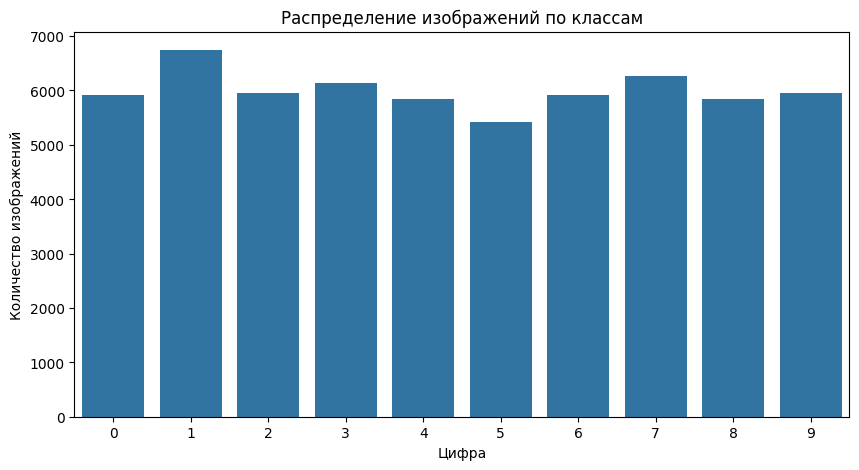

In [14]:
class_counts = pd.Series(y_train).value_counts().sort_index()

print("Количество изображений каждого класса:")
print(class_counts)

plt.figure(figsize=(10, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Распределение изображений по классам")
plt.xlabel("Цифра")
plt.ylabel("Количество изображений")
plt.show()

MNIST содержит изображения десяти классов — цифр от 0 до 9. Распределение изображений между классами достаточно равномерное. Существенного дисбаланса классов не наблюдается.

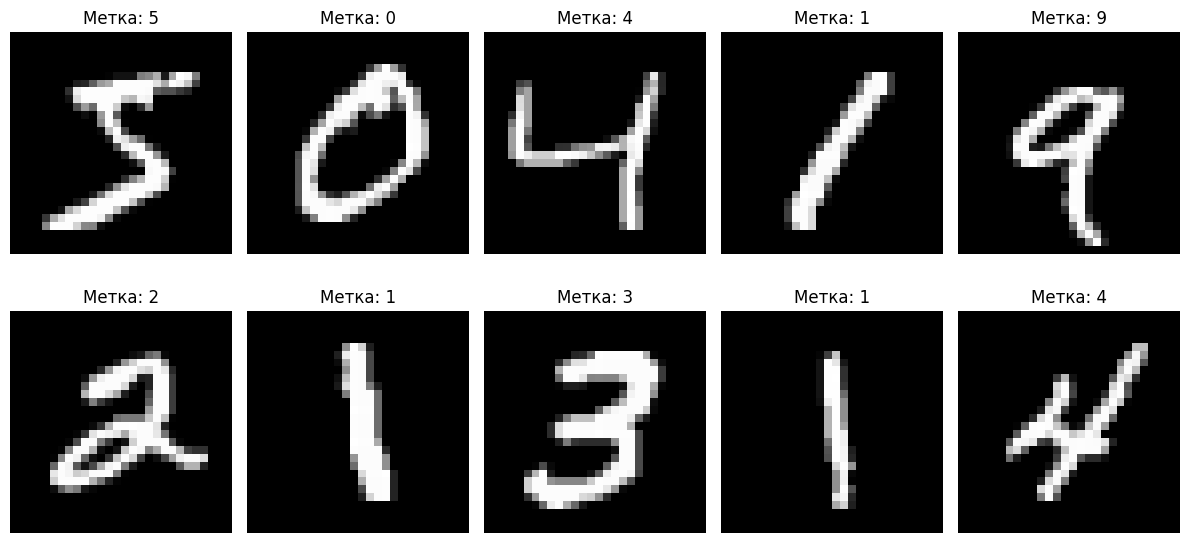

In [15]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_images[i], cmap='gray')
    plt.title(f"Метка: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [16]:
X_train = X_train_images.reshape(len(X_train_images), -1) / 255.0
X_test = X_test_images.reshape(len(X_test_images), -1) / 255.0

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

Размер обучающей выборки: (60000, 784)
Размер тестовой выборки: (10000, 784)


In [19]:
models = {
    "Дерево без ограничения глубины": DecisionTreeClassifier(
        random_state=42
    ),

    "Дерево с ограничением глубины": DecisionTreeClassifier(
        max_depth=20,
        random_state=42
    ),

    "Случайный лес": RandomForestClassifier(
        n_estimators=30,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ),

    "Бустинг": HistGradientBoostingClassifier(
        max_iter=50,
        random_state=42
    )
}

In [20]:
results = []

for name, model in models.items():
    print(f"\nОбучение модели: {name}", flush=True)

    start_time = time.time()

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    train_time = time.time() - start_time
    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Модель": name,
        "Accuracy": accuracy,
        "Время выполнения (сек)": train_time
    })

    print(f"Точность: {accuracy:.4f}")
    print(f"Время выполнения: {train_time:.2f} сек.")


Обучение модели: Дерево без ограничения глубины
Точность: 0.8754
Время выполнения: 25.41 сек.

Обучение модели: Дерево с ограничением глубины
Точность: 0.8818
Время выполнения: 20.46 сек.

Обучение модели: Случайный лес
Точность: 0.9632
Время выполнения: 12.63 сек.

Обучение модели: Бустинг
Точность: 0.9701
Время выполнения: 251.12 сек.


In [21]:
results_df = pd.DataFrame(results)

print("СРАВНЕНИЕ МОДЕЛЕЙ")
display(results_df.sort_values("Accuracy", ascending=False))

СРАВНЕНИЕ МОДЕЛЕЙ


,Модель,Accuracy,Время выполнения (сек)
3,Бустинг,0.9701,251.118231
2,Случайный лес,0.9632,12.632341
1,Дерево с ограничением глубины,0.8818,20.455494
0,Дерево без ограничения глубины,0.8754,25.408683


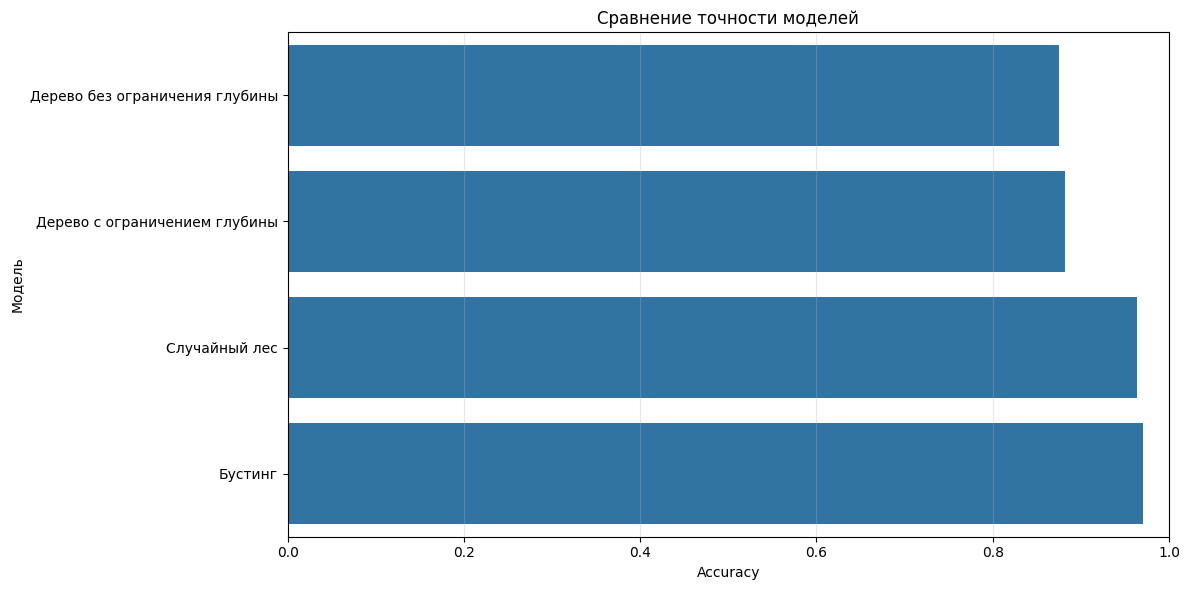

In [22]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Модель"
)

plt.title("Сравнение точности моделей")
plt.xlabel("Accuracy")
plt.ylabel("Модель")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

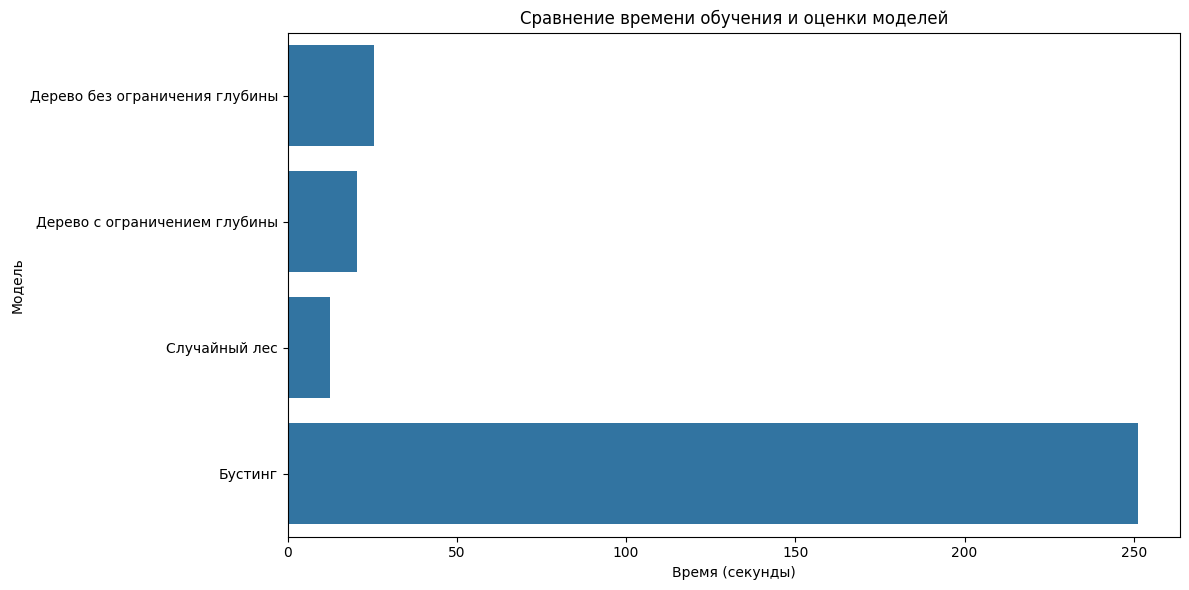

In [23]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Время выполнения (сек)",
    y="Модель"
)

plt.title("Сравнение времени обучения и оценки моделей")
plt.xlabel("Время (секунды)")
plt.ylabel("Модель")
plt.tight_layout()
plt.show()

In [24]:
best_model = results_df.loc[results_df["Accuracy"].idxmax()]

print("Лучшая модель:", best_model["Модель"])
print("Точность:", round(best_model["Accuracy"], 4))
print("Время выполнения:", round(best_model["Время выполнения (сек)"], 2), "сек.")

Лучшая модель: Бустинг
Точность: 0.9701
Время выполнения: 251.12 сек.


В ходе работы был загружен и проанализирован датасет MNIST с изображениями рукописных цифр от 0 до 9. Были обучены и сравнены четыре модели классификации: дерево решений без ограничения глубины, дерево с ограничением глубины, случайный лес и градиентный бустинг. Качество моделей оценивалось с помощью метрики Accuracy и времени выполнения.

По результатам сравнения была определена наиболее эффективная модель для классификации изображений MNIST.